# Project 3 - Robotic Process Automation

**You may NOT use any type of AI (artificial intelligence) bot such as ChatGPT to assist you on this project.**

You are the accountant for **PythonTech Co.**, a small business that sells tech products. When a customer places an order, they fill out an order form specifying the products they wish to purchase. You have received four of these order forms (`Order1.xlsx`, `Order2.xlsx`, `Order3.xlsx`, and `Order4.xlsx`). Here is an example of what these orders contain:

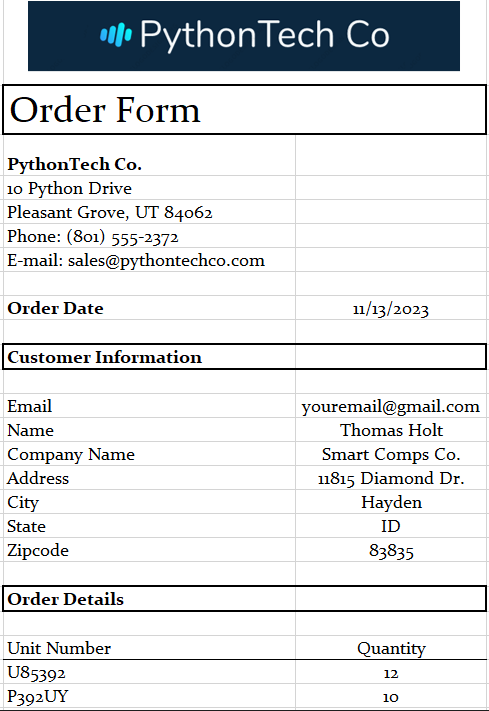

Your first task in this project is to extract all relevant order data from these order forms and create invoices to bill each customer using the `MasterInvoice.pdf` file. Below is an example of what a filled-out invoice looks like:


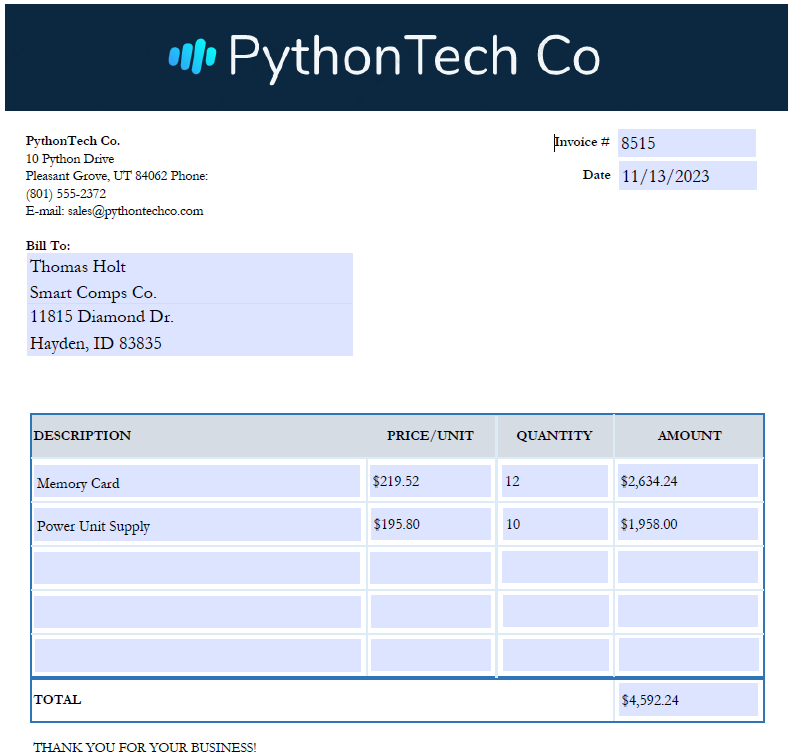

Then, you'll send emails to each customer including the customer's invoice as an attachment.


**The email in each** `Order` **Excel file is** `youremail@gmail.com`**. Before starting the project, please manually open each** `Order` **file and change the email to be your own personal email address.**

Use the cell below to import any packages you need as you work on this project.

In [3]:
# IMPORT PACKAGES IN THIS CELL

import os
import openpyxl
import pandas as pd
import smtplib
import mimetypes
from email.message import EmailMessage
from analyticskit import *

pd.options.display.float_format = '{:,.2f}'.format # Display option to include 2 decimal places on all floats
pd.set_option('display.max_columns', None) # Display option to show all columns
pd.set_option('display.max_rows', None) # Display option to show all rows

## Question 1

Obtain user input for the directory where the `ProductData.xlsx`, `MasterInvoice.pdf`, and `Order` (e.g., `Order1.xlsx`, `Order2.xlsx`, etc.) files are located.

1. Save the directory in a variable called `directory`.

2. Write code to ensure that the `directory` variable ends with `\\` (PC Users) or `/` (Mac Users). If it does not, add it. For example, if the user inputs `C:\Programs\ACC 525`, you can write code to add `\` to the end of the `directory` so that it is changed to `C:\Programs\ACC 525\`. **PC Users**: please note that `\\` is considered to be a **single character** in Python. The first `\` is an escape which Python does not consider to be a character.

3. Validate that the `directory` entered by the user contains the `ProductData.xlsx`, `MasterInvoice.pdf`, `Order1.xlsx`, `Order2.xlsx`, `Order3.xlsx`, and `Order4.xlsx` files. If not, prompt the user to re-enter the directory. Only allow the program to proceed when the user inputs the directory containing these files.

**PLEASE NOTE:** Throughout the remainder of the project, you must use the `directory` variable when opening or saving any file.

In [4]:
# INSERT ANSWER FOR QUESTION 1 HERE
def get_dir():
    directory = select_file('Please select a file in the directory you would like to select.')
    split_directory = directory.split('/')
    del split_directory[-1]
    directory = '/'.join(split_directory)
    directory = directory + '/'
    return directory


while True:
    directory = get_dir()
    files = os.listdir(directory)
    if 'ProductData.xlsx' in files and 'MasterInvoice.pdf' in files and 'Order1.xlsx'in files and "Order2.xlsx" in files and 'Order3.xlsx' in files and 'Order4.xlsx' in files:
        break
    else:
        show_message('Error', 'Please Enter the directory where the order files, product data file, and master invoice pdf are found.')
            

print(directory)



C:/Users/mrowe/School/2026-2027 (Y1 MAcc)/Fall 2026/Analytics (Python)/Advanced Analytics/17 - Project 3 - Robotic Process Automation/


## Question 2

In the next Question of this project, you will need to obtain the prices and descriptions for items on your order forms. To facilitate this, in this Question, you will create two dictionaries: `product_descriptions` and `product_prices`. These dictionaries will have the `Unit number` as key and the `Price per unit` or `Description` as values.

1\. Read in the `Descriptions` sheet from the `ProductData.xlsx` file into a `pandas` DataFrame. Reference the `directory` variable when reading in this data. Iterate over each row and create a dictionary called `product_descriptions` containing the `Unit number` as key and the `Description` as value.

2\. Read in the `Prices` sheet from the `ProductData.xlsx` file into a `pandas` DataFrame. Reference the `directory` variable when reading in this data. Iterate over each row in the DataFrame and create a dictionary called `product_prices` containing the `Unit number` as key and the `Price per unit` as value.

In [12]:
# INSERT ANSWER FOR QUESTION 2 HERE

product_descriptions = {}
product_prices = {}

product_data = directory + 'ProductData.xlsx'


def excel_to_dict(file, sheet, colname):
    df = pd.read_excel(file, sheet_name= sheet)
    new_dict = {}
    for _, row in df.iterrows():
        new_dict[row['Unit number']] = row[colname]
    return new_dict


product_descriptions = excel_to_dict(product_data, 'Descriptions', 'Description')
product_prices = excel_to_dict(product_data, 'Prices', 'Price per unit')


product_descriptions
product_prices

{'A2387F': 41.94,
 'B2380G': 456.4,
 'B2387D': 81.41,
 'B3N9JM': 186.42,
 'C2389J': 19.55,
 'C2K7FJ': 185.28,
 'CC7dRs3': 150.25,
 'D2398J': 254.05,
 'E2387G': 23.11,
 'F2387H': 17.6,
 'F3827D': 451.97,
 'F9834DR': 656.6,
 'G2387K': 44.35,
 'G2H8FJ': 2504.83,
 'G2K9HJ': 457.97,
 'H2389F': 407.4,
 'H23dHB8': 151.86,
 'H3452L': 252.3,
 'H3827G': 488.91,
 'I2387D': 804.36,
 'J2387G': 89.82,
 'J2987H': 451.13,
 'J9834DS': 1708.43,
 'K2387H': 457.23,
 'K5238RP': 25.0,
 'L2387K': 92.09,
 'LK8H9F': 458.34,
 'LK8J9F': 256.6,
 'M1238V892': 350.99,
 'M2387F': 186.31,
 'M2K8FJ': 42.97,
 'M38920VS': 15.0,
 'N2389D': 41.67,
 'N29KJ7': 85.25,
 'P2387H': 89.24,
 'P392UY': 195.8,
 'Q2387K': 48.49,
 'Q2930R': 451.84,
 'Q9876D': 88.03,
 'R1237G': 290.26,
 'R2389F': 251.84,
 'R27D4S': 457.03,
 'S2387D': 256.36,
 'S2D7K3': 158.7,
 'T2384D': 84.2,
 'U2387J': 90.02,
 'U85392': 219.52,
 'V2387G': 184.62,
 'V375DRS2': 68.82,
 'V3827H': 401.82,
 'W2K9FJ': 157.85,
 'X2389H': 99.81,
 'X3278F': 409.6,
 'X3920V': 

## Question 3

Create a function called `get_order_data` that takes three variables as inputs -- `invoice_num`, `filename` and `directory`:

1. The `invoice_num` is the invoice number (an integer) that we assign to this invoice.

2. The `filename` will be one of the order form files (e.g., `Order1.xlsx`).

3. The `directory` is the path to the folder containing the order form files (obtained in Question 1). You must reference this `directory` variable when opening these files.

The `get_order_data` function will process the order form and return four variables in the following order:

1. A dictionary containing the order data. Use the dictionary format required to fill the `MasterInvoice.pdf` file.

2. The name of the customer.

3. The email of the customer.

4. The date of the order.

You can use the `get_pdf` function from class to identify the fields required to fill the `MasterInvoice.pdf` file. These fields will be used as the keys of the order data dictionary. **As a reminder, all values in your dictionary must be strings or you will get an error when you try to use it to fill out the** `MasterInvoice` **PDF template in Question 4.**

The `Date` should be included as a string in this format: `MM/DD/YYYY`.

The prices and descriptions for each product on the order form can be obtained from the `product_prices` and `product_descriptions` dictionaries created in Question 2 based on the unit number of the product.

The order `Total` is calculated as the sum of `price x quantity` for all products on the order form.

Test your function by creating variables called `order_data`, `name`, `email`, and `date` that obtain the returned values when passing `8515` as the `invoice_num`, `Order1.xlsx` as the `filename` and the `directory` obtained from Question 1 into the `get_order_data` function. Manually inspect these variables to ensure they are returned as expected.

**Note:** Your code must allow for at least three products in the Order files. In other words, it is acceptable to write the code to handle one, two, or three products. If you'd like to push yourself, feel free to write code to handle any number of products in the Order files (HINT: a `while` loop might prove useful). Just know that handling more than three products is not required to successfully complete this Question.

**Hint:** To format a number in a currency format, you can use code like this:

<div style="margin-left: 2em;">

```
num = 29000.1
numstr = f'${num:,.2f}'
```

</div>

The `numstr` variable would be a string in format `$29,000.10`.

In [ ]:
# INSERT ANSWER FOR QUESTION 3 HERE

orders = ['Order1.xlsx', 'Order2.xlsx', 'Order3.xlsx', 'Order4.xlsx']

def get_order_data(invoice_num, filename, directory=directory):
    wb = openpyxl.load_workbook(directory + filename, data_only=True)
    ws = wb['OrderForm']
    order_date = ws['C9'].value
    email = ws['C13'].value
    cust_name = ws['C14'].value
    comp_name = ws['C15'].value
    street_address = ws['C16'].value
    city = ws['C17'].value
    state = ws['C18'].value
    zipcode = ws['C19'].value

    start_row = 24
    cols = ['B', 'C']
    while True:
        
    

    unit_num0 = ws['B24'].value
    unit_qty0 = ws['C24'].value
    unit_num1 = ws['B25'].value
    unit_qty1 = ws['C25'].value
    unit_num2 = ws['B26'].value
    unit_qty2 = ws['C26'].value


pdf_dict = {}
pdf_dict = get_pdf('Example Invoice.pdf')
pdf_dict

# get_order_data(0, 'Order1.xlsx', directory)

,name,type,value
0,InvoiceNum,/Tx,1000
1,Date,/Tx,11/05/2026
2,Total,/Tx,100.00
3,CustomerAddress1,/Tx,Address pt. 1
4,CustomerName,/Tx,Customer Name
5,CustomerCompany,/Tx,Customer Company
6,CustomerAddress2,/Tx,Address pt. 2
7,Price0,/Tx,1
8,Quantity0,/Tx,1
9,Amount0,/Tx,1


## Question 4

Create a function called `create_invoice` that takes three variables as inputs -- `invoice_num`, `order_data`, and `directory`:

1. The `invoice_num` is the invoice number (an integer) that we assign to this invoice

2. The `order_data` is the dictionary we obtain from the `get_order_data` function in Question 3.

3. The `directory` is the path to the folder containing the `MasterInvoice.pdf` file (obtained in Question 1). You must reference this `directory` variable when opening the `MasterInvoice.pdf` file and when saving the new invoice PDF file.

The `create_invoice` function will use the `order_data` to fill out the `MasterInvoice.pdf` template and save the template as `'Invoice ####.pdf'` (e.g., `'Invoice 8515.pdf'`) in the same location as the `MasterInvoice.pdf` file. See the screenshot at the top this project for an example of a filled-out invoice. Note: the `create_invoice` function does not return anything.

Test your function by passing `8515` as the `invoice_num`, the `order_data` dictionary obtained from Question 3, and the `directory` obtained from Question 1 into the `create_invoice` function. Manually inspect your `'Invoice 8515.pdf'` file to ensure it matches the example invoice above.

**Note:** If you are on a Mac and you adjust the `MasterInvoice.pdf` file (or perhaps even open it!), it will give you an error when you try to use `pypdf`. If this happens, re-download the `MasterInvoice.pdf` file and it should work.

 

In [7]:
# INSERT ANSWER FOR QUESTION 4 HERE


## Question 5

Create a function called `send_email` that takes five variables as inputs -- `invoice_num`, `name`, `email`, `date`, and `directory`:

1. The `invoice_num` is the invoice number (an integer) that we assign to this invoice.

2. The `name` is the name of the customer, which we obtain from from the `get_order_data` function in Question 3.

3. The `email` is the email of the customer, which we obtain from the `get_order_data` function in Question 3.

4. The `date` is the date of the order, which we obtain from the `get_order_data` function in Question 3.

5. The `directory` is the path to folder of the invoice file, which we obtained in Question 1. You must reference this `directory` variable when attaching the invoice file.

The `send_email` function will send an email to a customer including the invoice we created in Question 4. Below is an example of the content of the email:

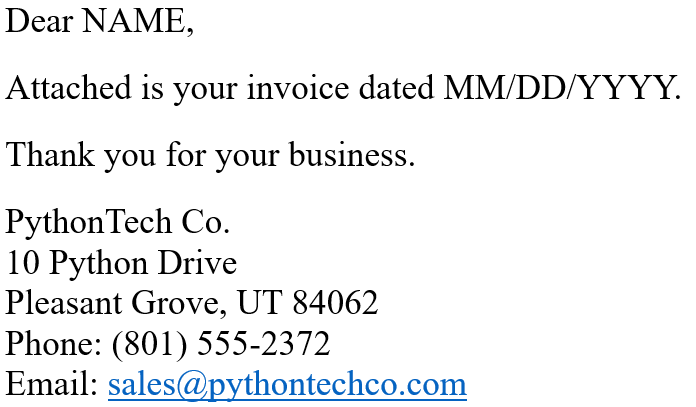

The email should include the following options:


1. Subject: `Your Order from PythonTech Co. - Invoice XXXX` -- replacing XXXX with the correct invoice number.

2. Body:

   1. Use appropriate spacing for the body of the email including line breaks.

   2. Fill in `'NAME'` with the customer's name.

   3. Fill in the `'MM/DD/YYYY'` with the Invoice Date in the format `MM/DD/YYYY`.

3. Attachment: `Invoice XXXX.pdf` (using the invoice based on the `invoice_num`, and using the full path to the attachment (i.e., referencing the `directory` variable)).

Note: the `create_invoice` function does not return anything.

Note: the `sales@pythontechco.com` email does not need to be hyperlinked in your sent email.

Test your function by passing `8515` as the `invoice_num`, the `'Thomas Holt'` as the `name`, your email address as the `email`, `'11/13/2023'` as the `date`, and the `directory` obtained from Question 1 into the `send_email` function. Manually inspect your email to ensure it was sent properly.

In [8]:
# INSERT ANSWER FOR QUESTION 5 HERE


## Question 6

1. Create a list called `filenames` containing all filenames in the `directory` obtained in Question 1 (e.g., `Order1.xlsx`, `Order2.xlsx`, etc.). You cannot hard code these file names into the list. You must use Python code to obtain them. If you are on a Mac, sort the filenames so they are in alphabetical order.

2. Loop through the `filenames` list and for each filename, if `'Order'` and `'xlsx'` are in the filename do the following:

   1. Use the `get_order_data` function to obtain the `order_data`, `name`, `email`, and `date` for the order.

   2. Use the `create_invoice` function to create the invoice pdf file.

   3. Use the `send_email` function to send the email.

Use `invoice_num` equal to `8515` for the first Order, `8516` for the second order, etc.

**NOTE:** You are permitted to hard code a variable (e.g., `invoice_num`) with value equal to `8515` as your starting invoice number and then increment that variable for each additional invoice.

**MAC USERS:** Before you begin the `for` loop, you may need to sort your `filenames` list so that the Order Excel files are in the correct order.

In [9]:
# INSERT ANSWER FOR QUESTION 6 HERE


## Question 7

Use the <https://github.com/joshlee84/app-distribution-template> to create a new GitHub repository called `rpa-project`.

1. Update the `app.toml` file. Set `name` equal to `"RPAProject"` and `display_name` equal to `"RPA Project"`.

2. Update the `requirements.txt` file to include the Python modules required by your script. **Note:** The following modules are built into Python and do not need to be placed in `requirements.txt`: `os`, `smtplib`, `mimetypes`, `email.message`.

3. Replace the contents of `app.py` with the code from Questions 1 to 6 of this project. **Note:** For Question 5, replace `gmail_password = open('gmail_password.txt').read()` with `gmail_password_path = select_file('Please select the gmail password file')` and `gmail_password = open(gmail_password_path).read().` For these two lines of code, it might be useful to take them out of your `send_email` function, and place them in your code before the function as global variables. This will prevent you from being prompted to select the gmail password file multiple times when you run the code.

4. Commit and push your updates to your GitHub repository. Then create and push a new tag to start the automatic GitHub Action which will convert your project into executable files.

5. In the cell below, paste the link to your GitHub `rpa-project` releases page containing the executable files for your project. It should look something like this: <https://github.com/github-username/rpa-project/releases>

**Note: The only code required to be turned in for this question is a commented link to the GitHub** `rpa-project` **releases page with your executable files. You are not required to turn in your GitHub repository files.**

Note 2: You'll need to either copy and paste your \`gmail_password.txt\` file in your

In [10]:
# INSERT ANSWER FOR QUESTION 7 HERE

# INSERT YOUR LINK HERE AS A COMMENT